# Week-7

Decision trees and KNN

In [ ]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [8, 8]
plt.rcParams['font.size'] = 15

## Decision Trees

**Decision stumps**

A decision stump is a decision tree that has a single question at the root node which splits into two leaf nodes. A decision stump partitions the dataset based on a single question: $f_k < \theta$. This is therefore the simplest decision tree that we can come up with.

---
Use the following decision stump for problems 1 and 3: The root has $1000$ data-points out of which $200$ belong to class-1. The left child-node has $100$ data-points out of which $50$ belong to class-1.

### Problem-1

Write a function `entropy` that accepts the proportion of points that belong to class-1 in a node as argument and returns the entropy. Use $\log_2$ for all computations.

Use this function to compute the entropy of the parent node.

In [ ]:
### Solution ###

def entropy(p):
  if p == 1 or p==0:
    return 0
  return -(p*np.log2(p) + (1-p)*(np.log2(1-p)))

fract_1s_root = 200/1000
root_entropy = entropy(fract_1s_root)
print(round(root_entropy,3))

0.722


### Problem-2

Plot the entropy of a node as a function of $p$, the proportion of data-points that belong to class $+1$.

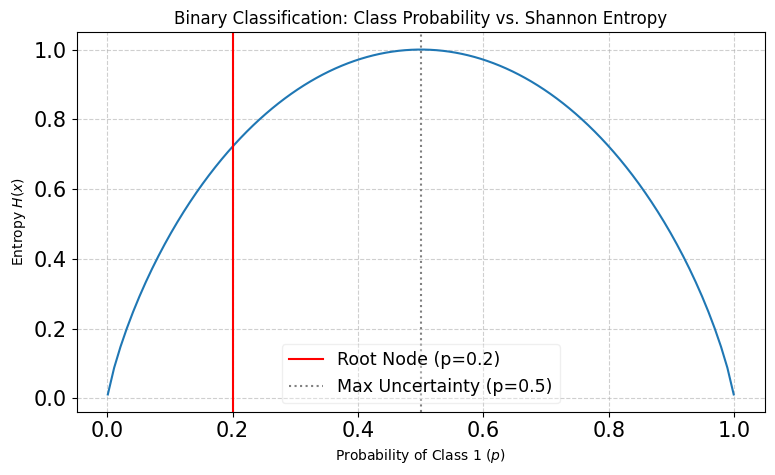

In [ ]:
### Solution ###
p = np.linspace(0.001, 0.999, 100)

plt.figure(figsize=(8,5))
plt.plot(p, -(p*np.log2(p) + (1-p)*(np.log2(1-p))))
plt.axvline(fract_1s_root,color='red',label=f"Root Node (p={fract_1s_root})")
plt.axvline(0.5, color='gray', linestyle=':', label='Max Uncertainty (p=0.5)')

plt.title("Binary Classification: Class Probability vs. Shannon Entropy",fontsize=12)
plt.xlabel('Probability of Class 1 ($p$)',fontsize=10)
plt.ylabel("Entropy $H(x)$",fontsize=10)
plt.grid(True,linestyle="--",alpha=0.6)
plt.legend(fontsize='small', framealpha=0.3)
plt.tight_layout()
plt.show()

### Problem-3

Write a function `IG` that accepts the following arguments:

- `E`: entropy of the parent node `Q`
- `El`: entropy of the left child `L`
- `Er`: entropy of the right child `R`
- `gamma`: proportion of data-points in left child

Use this function to compute the information gain for the parent node.

Use the following decision stump for problems 1 and 3: The root has $1000$ data-points out of which $200$ belong to class-1. The left child-node has $100$ data-points out of which $50$ belong to class-1

In [ ]:
### Solution ###
def IG(E,El,Er,gamma):
  return E - (gamma * El + (1-gamma)*Er)

root_frac = 200/1000
left_frac = 50/100
gamma = 100/1000
right_frac = 150/900

IG(entropy(root_frac),entropy(left_frac),entropy(right_frac),gamma)

np.float64(0.03690791540384364)

### Problem-4

Consider a decision stump with $1000$ data-points. Call the root node $Q$ and the left and right leaf nodes $L$ and $R$.

- The proportion of data-points that belong to class $+1$ in $Q$ is equal to $0.4$
- The proportion of points in the left node is equal to $0.7$, that is, $\gamma = 0.7$
-  $q$ is the proportion of data-points that belong to class $+1$ in $L$

What are the minimum ($q_{\min}$) and maximum ($q_{\max}$) values of $q$?

In [ ]:
### Solution ###
root_frac = 0.4
gamma = 0.7

"""
root_node = 1000, {400:1s} {600:0s}
left_node = 700,
right_node = 300

"""

qmax = 400/700
qmin = 100/700
[qmin,qmax]

[0.14285714285714285, 0.5714285714285714]

In [ ]:
### Solution ###
n = 1000
p = 0.4
gamma = 0.7
qmax = min(p / gamma, 1)
qmin = max(0, (p + gamma - 1) / gamma)
print(f'Q_min = {qmin:.2f}, Q_max = {qmax:.2f}')

Q_min = 0.14, Q_max = 0.57


### Problem-5

Using the above information, plot the information gain of the root as a function of $q$, where $q \in [q_{\min}, q_{\max}]$. Record at least two interesting observations.

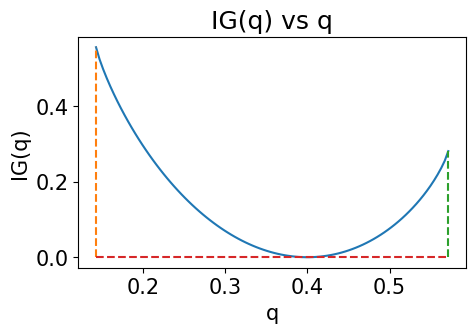

In [ ]:
### Solution ###

p = 0.4
q = np.linspace(qmin,qmax,100)
r = (p-(gamma*q))/(1-gamma)

E = entropy(p)
El = np.array([entropy(x) for x in q])
Er = np.array([entropy(y) for y in r])

IG_values = IG(E,El,Er,gamma)

plt.figure(figsize=(5,3))
plt.plot(q,IG_values)
plt.plot([qmin,qmin],[0,IG_values[q==qmin].item()],"--")
plt.plot([qmax,qmax],[0,IG_values[q==qmax].item()],"--")
plt.plot([qmin, qmax], [0, 0], '--')

plt.title("IG(q) vs q")
plt.xlabel('q')
plt.ylabel('IG(q)')

plt.show()

### Problem-6

We will work with the dataset `X` for the next five problems. Visualize the data using a scatter plot. Color the points that belong to class $+1$ using "green" and those that belong to class $0$ using "red".

In [ ]:
### Data ###
### DO NOT CHANGE THE CONTENTS OF THIS CELL ###
rng = np.random.default_rng(seed = 1001)
n_per = 50
cov = np.eye(2) / 10
X1 = rng.multivariate_normal([1, 1], cov, n_per)
y1 = np.ones(n_per)
X2 = rng.multivariate_normal([5, 3], cov , n_per)
y2 = np.zeros(n_per)
X3 = rng.multivariate_normal([3, 4], cov, n_per)
y3 = np.ones(n_per)
X4 = rng.multivariate_normal([3, 2], cov, n_per)
y4 = np.zeros(n_per)
X = np.concatenate((X1, X2, X3, X4), axis = 0)
y = np.int64(np.concatenate((y1, y2, y3, y4)))
### DO NOT CHANGE THE CONTENTS OF THIS CELL ###

In [ ]:
### Solution ###

### Problem-7

If you were to use a decision stump as a classifier:

- What is the best question $f_k < \theta$?
    - enter the feature index, $k$ (use zero-indexing)
    - enter the value of $\theta$
- What is the information gain for this question?

---

Write the function named `best_split` to solve this problem:

The function should accept the feature matrix `X` and the label vector `y` as arguements. It should return the tuple `(feat_best, value_best, ig_best)`.

In [ ]:
### Solution ###

### Problem-8

Grow a decision tree for this problem. You may have to use two programming concepts:

- recursion
- binary trees

Once you have grown the tree, answer the following questions:

- How many internal nodes does your tree have?
- How many leaf nodes does it have?

In [ ]:
### Solution ###

### Problem-9

Predict the label of the point $(3, 4)$.

In [ ]:
### Solution ###

### Problem-10

Plot the decision boundary.

In [ ]:
### Solution ###

## KNN


In [ ]:
### Data ###
### DO NOT EDIT THIS CELL ###
rng = np.random.default_rng(seed = 1001)
X = rng.uniform(-10, 10, (100, 2))
y = np.int32(np.zeros(X.shape[0]))
y[X[:, 1] > X[:, 0]] = 1
X = np.concatenate((X,
                   rng.multivariate_normal([-5, 5], np.eye(2), 10)),
                   axis = 0)
y = np.concatenate((y, np.int32(np.zeros(10))))
### DO NOT EDIT THIS CELL ###

### Problem-11

Visualize the data using a scatter plot. Use red for class $0$ and green for class $1$.

In [ ]:
### Solution ###

### Problem-12

Write a function `predict` that accepts the following arguments:

- `X` - feature matrix
- `y` - label vector
- `x_test` - test data-point
- `k` - number of neighbors

The function should return the prediction for the point `x_test`. Use this function to compute the predicted label for the point $(-3, -2)$ with $k = 10$.

In [ ]:
### Solution ###

### Problem-13

Plot the decision boundary for different values of $k$:

- $k = 1$
- $k = 3$
- $k = 7$
- $k = 15$
- $k = 31$
- $k = 63$

Record at least two observations.

In [ ]:
### Solution ###